# Exploring the IBL mouse decision data

Five plots for getting to know `data/ibl_trials.csv` before (or after) running
the models in `rnn_vs_dnn_ibl.py`, plus a bonus on reaction times:

1. **Session overview**: how many trials, how accurate, and whether the mouse uses the hidden block
2. **Psychometric curves by block**: the signature IBL plot
3. **Choices aligned to block switches**: how fast the mouse adapts
4. **Trial-history effects**: the previous trial vs the current block
5. **Block lengths**: what the hidden structure looks like
6. *Bonus*: response times, from the new timing columns

Open it with the **Python (ibl)** kernel (see the README's Setup section).
Only pandas, numpy and matplotlib are needed, so any kernel with those works
too. All numbers come from `ibl_analysis.py`, which the GUI
(`python ibl_explorer.py`) also uses; the GUI is the place to click around.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ibl_analysis as ia

C = ia.COLORS
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"],
    "axes.edgecolor": C["axis"], "axes.labelcolor": C["ink"], "text.color": C["ink"],
    "xtick.color": C["ink_secondary"], "ytick.color": C["ink_secondary"],
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titlelocation": "left", "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110,
})


def ref_line(ax, y=None, x=None):
    """Thin dotted reference line (chance, zero contrast, block switch)."""
    kw = dict(color=C["muted"], lw=1, ls=":", zorder=0)
    ax.axhline(y, **kw) if y is not None else ax.axvline(x, **kw)


raw = pd.read_csv("data/ibl_trials.csv")
df = ia.prepare(raw)  # derived columns, computed once on the full table
print(f"{len(df):,} trials, {df['session_idx'].nunique()} sessions, "
      f"{df['date'].min()} to {df['date'].max()}")
df.head()

37,546 trials, 40 sessions, 2019-07-18 to 2019-09-19


,session_id,session_idx,session_start_time,trial_in_session,choice,contrastLeft,contrastRight,feedbackType,probabilityLeft,goCue_times,...,date,prev_chose_right,prev_correct,block_id,trial_in_block,block_len,prev_block_p,next_block_p,response_time,movement_time
0,7f353dea-d694-4e5b-92ce-1a6d03344cb8,0,2019-07-18T11:14:07.933334,0,1,NaN,0.125,-1,0.5,1.5758,...,2019-07-18,NaN,NaN,0,0,90,NaN,0.8,0.5660,0.261953
1,7f353dea-d694-4e5b-92ce-1a6d03344cb8,0,2019-07-18T11:14:07.933334,1,-1,NaN,1.000,1,0.5,5.6903,...,2019-07-18,0.0,0.0,0,1,90,NaN,0.8,0.2410,-0.011547
2,7f353dea-d694-4e5b-92ce-1a6d03344cb8,0,2019-07-18T11:14:07.933334,2,1,0.0625,NaN,1,0.5,8.9067,...,2019-07-18,1.0,1.0,0,2,90,NaN,0.8,0.2388,0.057053
3,7f353dea-d694-4e5b-92ce-1a6d03344cb8,0,2019-07-18T11:14:07.933334,3,1,NaN,0.000,-1,0.5,13.8404,...,2019-07-18,0.0,1.0,0,3,90,NaN,0.8,4.3309,0.028353
4,7f353dea-d694-4e5b-92ce-1a6d03344cb8,0,2019-07-18T11:14:07.933334,4,1,1.0000,NaN,1,0.5,21.6594,...,2019-07-18,0.0,0.0,0,4,90,NaN,0.8,0.1585,0.036353


### The columns

| Column | Meaning |
|---|---|
| `choice` | **-1 = mouse reported RIGHT**, +1 = LEFT (no-go trials were dropped) |
| `contrastLeft` / `contrastRight` | stimulus contrast as a fraction; exactly one is set, the other is NaN. That's also how a 0 % trial has a "correct side". |
| `feedbackType` | +1 rewarded, -1 error |
| `probabilityLeft` | the hidden block: 0.8 = left block, 0.2 = right block, 0.5 = the unbiased first 90 trials of every session |
| `goCue_times`, `firstMovement_times`, `response_times` | seconds on the session clock (new; used in the bonus section) |

`ia.prepare` adds `signed_contrast` (right positive), `chose_right`, `correct`,
the previous trial's choice/outcome (never crossing a session boundary),
block ids and positions, and `response_time` / `movement_time` relative to
the go cue.

## 1. Session overview

Three questions for every session: how many trials, how accurate, and does
the mouse use the hidden block? The last one is measured on **0 % contrast
trials in biased blocks**: there is no stimulus to see, so choosing the
block's side more than half the time can only come from tracking the block.

Block-following, first 10 sessions: 0.64; last 10: 0.70


,n_trials,accuracy,easy_accuracy,follows_block_0,median_response_time
mean,938.65,0.868,0.991,0.672,0.310
min,559.00,0.822,0.953,0.539,0.204
max,1259.00,0.901,1.000,0.751,0.449


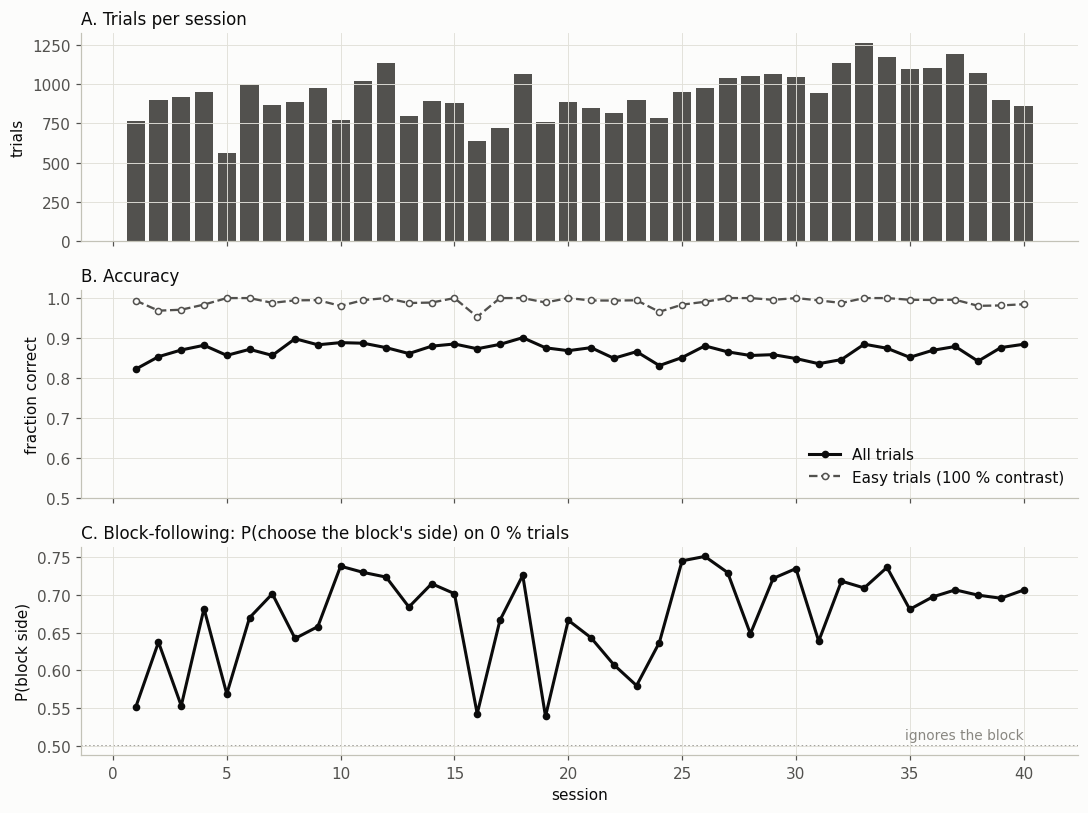

In [2]:
summary = ia.session_summary(df)
x = summary["session_idx"] + 1

fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
ax = axes[0]
ax.bar(x, summary["n_trials"], width=0.8, color=C["ink_secondary"])
ax.set(title="A. Trials per session", ylabel="trials")

ax = axes[1]
ax.plot(x, summary["accuracy"], "-o", color=C["ink"], lw=2, ms=4, label="All trials")
ax.plot(x, summary["easy_accuracy"], "--o", color=C["ink_secondary"], lw=1.5, ms=4,
        mfc=C["surface"], label="Easy trials (100 % contrast)")
ax.set(title="B. Accuracy", ylabel="fraction correct", ylim=(0.5, 1.02))
ax.legend(loc="lower right")

ax = axes[2]
ref_line(ax, y=0.5)
ax.text(x.max(), 0.505, "ignores the block", color=C["muted"], ha="right", va="bottom",
        fontsize=9)
ax.plot(x, summary["follows_block_0"], "-o", color=C["ink"], lw=2, ms=4)
ax.set(title="C. Block-following: P(choose the block's side) on 0 % trials",
       xlabel="session", ylabel="P(block side)")
fig.tight_layout()

first, last = summary.head(10), summary.tail(10)
print(f"Block-following, first 10 sessions: {first['follows_block_0'].mean():.2f}; "
      f"last 10: {last['follows_block_0'].mean():.2f}")
summary.drop(columns="session_idx").describe().loc[["mean", "min", "max"]].round(3)

**What to notice**

- Sessions run 559 to 1,259 trials. Accuracy on easy (100 %) trials averages 0.99, so the mouse knows the task; overall accuracy (0.82 to 0.90) is held down by the low-contrast trials.
- Block-following is above 0.5 in every session (0.54 to 0.75) and rises from 0.64 over the first 10 sessions to 0.70 over the last 10. It is noisy from session to session.
- Four of the five shortest sessions (1, 5, 16 and 19) are also four of the five weakest at following the block. A short session may mean a less engaged mouse. The GUI's Timeline tab is a quick way to look at those sessions.

## 2. Psychometric curves by block

P(chose right) at each signed contrast, one curve per block. Contrasts are
spaced evenly, since on a linear axis 6.25 % and 12.5 % would be squeezed
against 0. If the mouse uses the block, the curves shift sideways, and the
shift is largest at 0 %, where the stimulus carries no information.

signed_contrast,-1.0000,-0.2500,-0.1250,-0.0625,0.0000,0.0625,0.1250,0.2500,1.0000
probabilityLeft,,,,,,,,,
0.2,0.01,0.05,0.09,0.27,0.73,0.90,0.96,0.98,0.99
0.5,0.00,0.02,0.06,0.28,0.54,0.75,0.85,0.96,0.98
0.8,0.01,0.01,0.04,0.09,0.37,0.70,0.81,0.92,0.98


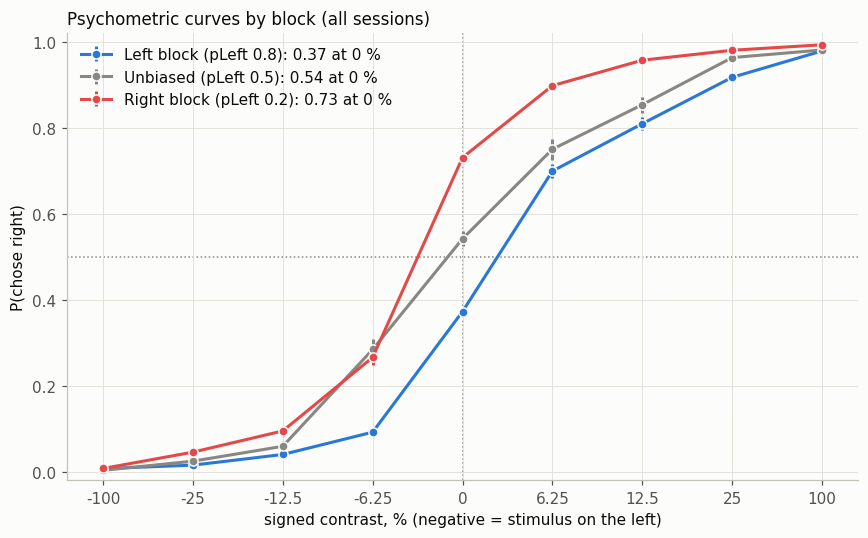

In [3]:
psy = ia.psychometric(df)
levels = sorted(psy["signed_contrast"].unique())
pos = {c: i for i, c in enumerate(levels)}

fig, ax = plt.subplots(figsize=(8, 5))
ref_line(ax, y=0.5)
ref_line(ax, x=pos[0.0])
for block in (ia.LEFT_BLOCK, ia.NEUTRAL_BLOCK, ia.RIGHT_BLOCK):
    t = psy[psy["probabilityLeft"] == block]
    at_zero = t.loc[t["signed_contrast"] == 0, "p_right"].iloc[0]
    ax.errorbar(t["signed_contrast"].map(pos), t["p_right"], yerr=t["sem"],
                color=ia.BLOCK_COLORS[block], lw=2, marker="o", ms=6, mec=C["surface"],
                label=f"{ia.BLOCK_LABELS[block]}: {at_zero:.2f} at 0 %")
ax.set_xticks(range(len(levels)), [f"{100 * c:g}" for c in levels])
ax.set(title="Psychometric curves by block (all sessions)", ylim=(-0.02, 1.02),
       xlabel="signed contrast, % (negative = stimulus on the left)",
       ylabel="P(chose right)")
ax.legend(loc="upper left")
fig.tight_layout()

psy.pivot(index="probabilityLeft", columns="signed_contrast", values="p_right").round(2)

**What to notice**

- At 100 % contrast the three curves meet: when the stimulus is obvious, the block doesn't matter.
- At 0 % they are far apart: P(right) is **0.73** in the right block, **0.54** in the unbiased block and **0.37** in the left block. That gap of 0.36 is the mouse using the hidden prior.
- The prior still tips weak but visible stimuli: at +6.25 % P(right) is 0.90 in the right block vs 0.70 in the left block.
- The unbiased curve passes 0.54 at 0 %: this mouse has a small rightward bias of its own.

## 3. Choices aligned to block switches

Line up every switch between the two biased blocks (0.2 <-> 0.8) and plot
P(choice = the new block's side) against trials since the switch. Before
the switch the mouse should prefer the old side (below 0.5), and after it
should drift over to the new side.

**Which trials to use matters.** On visible-stimulus trials the mouse
mostly just reports the stimulus, and after a switch 80 % of stimuli come
from the new side. Pooled over all contrasts, the curve therefore jumps at
trial 0 even though the mouse has had no chance to notice anything yet.
Only 0 % trials show the mouse's own belief about the block. Panel B shows
both.

,10 before,trials 0-4,trials 5-9,trials 10-19,trials 20-39
0 % only,0.27,0.43,0.61,0.71,0.72
all contrasts,0.21,0.68,0.76,0.78,0.79


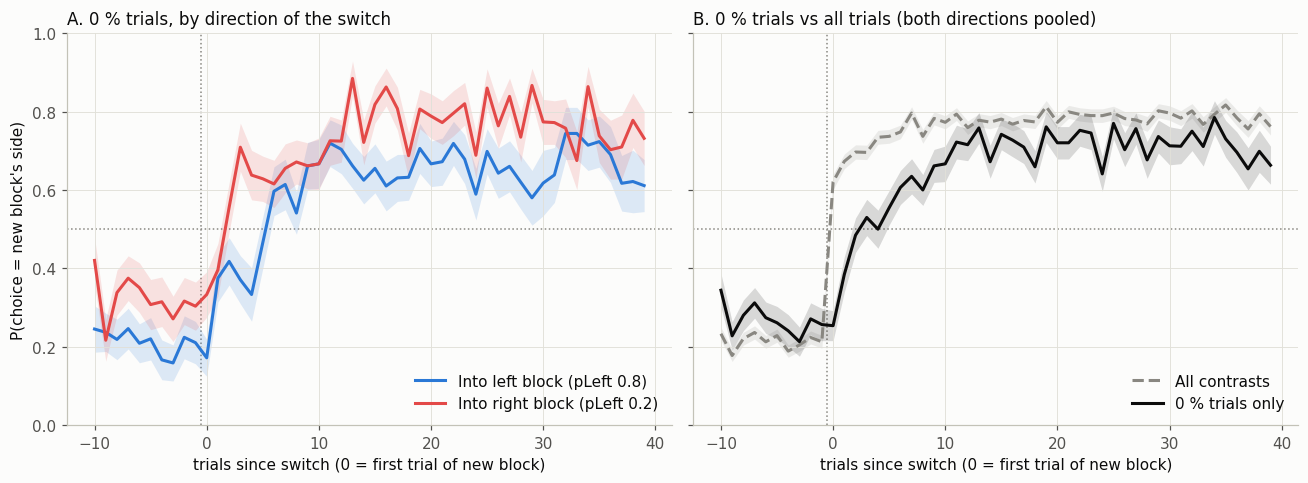

In [4]:
BEFORE, AFTER = 10, 40
by_direction = ia.block_switch_curve(df, BEFORE, AFTER, max_contrast=0.0, split=True)
zero_only = ia.block_switch_curve(df, BEFORE, AFTER, max_contrast=0.0, split=False)
all_contrasts = ia.block_switch_curve(df, BEFORE, AFTER, max_contrast=None, split=False)


def curve_with_band(ax, curve, color, label, ls="-"):
    ax.fill_between(curve["offset"], curve["p"] - curve["sem"], curve["p"] + curve["sem"],
                    color=color, alpha=0.15, lw=0)
    ax.plot(curve["offset"], curve["p"], color=color, lw=2, ls=ls, label=label)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
ax = axes[0]
for block in (ia.LEFT_BLOCK, ia.RIGHT_BLOCK):
    label = "Into " + ia.BLOCK_LABELS[block][0].lower() + ia.BLOCK_LABELS[block][1:]
    curve_with_band(ax, by_direction[by_direction["new_block"] == block],
                    ia.BLOCK_COLORS[block], label)
ax.set(title="A. 0 % trials, by direction of the switch",
       ylabel="P(choice = new block's side)")
ax = axes[1]
curve_with_band(ax, all_contrasts, C["muted"], "All contrasts", ls="--")
curve_with_band(ax, zero_only, C["ink"], "0 % trials only")
ax.set(title="B. 0 % trials vs all trials (both directions pooled)")
for ax in axes:
    ref_line(ax, y=0.5)
    ref_line(ax, x=-0.5)
    ax.set(xlabel="trials since switch (0 = first trial of new block)", ylim=(0, 1))
    ax.legend(loc="lower right")
fig.tight_layout()


def window_mean(curve, lo, hi):
    w = curve[curve["offset"].between(lo, hi)]
    return np.average(w["p"], weights=w["n"])


windows = {"10 before": (-10, -1), "trials 0-4": (0, 4), "trials 5-9": (5, 9),
           "trials 10-19": (10, 19), "trials 20-39": (20, 39)}
pd.DataFrame({name: {label: window_mean(curve, *w) for label, w in windows.items()}
              for name, curve in [("0 % only", zero_only), ("all contrasts", all_contrasts)]}
             ).T.round(2)

**What to notice**

- On 0 % trials (panel B, solid) the mouse goes from 0.27 before the switch (still favoring the old side) to 0.43 over the first 5 trials, 0.61 over trials 5 to 9, and levels off around 0.71 after about 10 trials. That gradual rise is what inferring a hidden state looks like: it takes several trials of evidence from the new side to change its mind.
- Pooled over all contrasts (dashed), the curve jumps to 0.68 right away. That's the stimuli changing sides, not the mouse adapting.
- Panel A shows an asymmetry: late in the block the mouse settles higher in right blocks (0.78) than in left blocks (0.66), consistent with its own rightward bias from section 2.
- This 0 % curve is the "real mouse" line in panel D of `rnn_vs_dnn_ibl.png`.

## 4. Trial-history effects

Does the **previous trial** sway the mouse, on top of the block? Take the
0 % trials and split them by what happened on the previous trial (which
side the mouse chose and whether it was rewarded) **and** by the current
block.

The split by block is the important part. "Previous choice = right" is
much more common in right blocks, so if you pooled the blocks, a block
effect would look like a history effect. Within one color below, the block
is fixed, so differences between groups come from the previous trial
alone.

p_right             n        
probabilityLeft     0.2   0.8     0.2     0.8
previous                                     
Left, rewarded     0.59  0.32   578.0  2385.0
Left, error        0.52  0.31   235.0   188.0
Right, rewarded    0.79  0.53  2371.0   587.0
Right, error       0.70  0.57   131.0   277.0

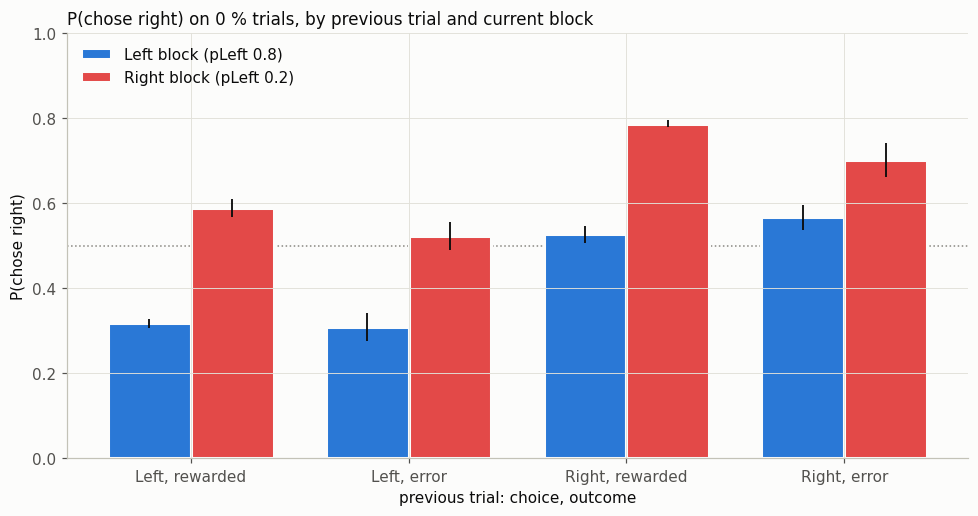

In [5]:
biased = ia.filter_trials(df, blocks=ia.BIASED_BLOCKS)
hist = ia.history_table(biased, contrast=0.0)

fig, ax = plt.subplots(figsize=(9, 4.8))
ref_line(ax, y=0.5)
width = 0.38
for k, block in enumerate((ia.LEFT_BLOCK, ia.RIGHT_BLOCK)):
    t = hist[hist["probabilityLeft"] == block]
    xs = t["previous"].cat.codes + (k - 0.5) * width
    ax.bar(xs, t["p_right"], width=width, color=ia.BLOCK_COLORS[block],
           edgecolor=C["surface"], linewidth=2, label=ia.BLOCK_LABELS[block])
    ax.errorbar(xs, t["p_right"], yerr=t["sem"], fmt="none", ecolor=C["ink"], elinewidth=1.2)
ax.set_xticks(range(len(ia.HISTORY_ORDER)), ia.HISTORY_ORDER)
ax.set(title="P(chose right) on 0 % trials, by previous trial and current block",
       xlabel="previous trial: choice, outcome", ylabel="P(chose right)", ylim=(0, 1))
ax.legend(loc="upper left")
fig.tight_layout()

hist.pivot(index="previous", columns="probabilityLeft", values=["p_right", "n"]).round(2)

**What to notice**

- The block dominates: in every group the right-block bar (red) is above the left-block bar (blue), by 0.13 to 0.27.
- Within a block, the previous **choice** matters: after a rewarded right choice, P(right) is about 0.2 higher than after a rewarded left choice, in both blocks (0.79 vs 0.59 and 0.53 vs 0.32). The mouse tends to repeat what it just did.
- Whether the previous trial was **rewarded** matters much less, and not consistently in one direction. Errors don't make the mouse switch sides: after a right error it still chooses right more often than after any left trial. So this isn't win-stay/lose-switch.
- One confound remains. A "previous right" trial inside a left block happens mostly just after a switch, while the mouse still believes in the old block. The exercises at the end ask you to control for it.

## 5. Block lengths

How long does a biased block last? Each session's **last** block is left
out because the session ended it early; keeping it would pull the lengths
down. The 5-trial memory that `DNN-window` gets in `rnn_vs_dnn_ibl.py` is
marked for comparison.

Unbiased opening block: 89 to 90 trials


,count,mean,std,min,25%,50%,75%,max
probabilityLeft,,,,,,,,
0.2,315.0,51.7,22.2,20.0,32.0,48.0,68.5,99.0
0.8,315.0,52.3,21.8,18.0,34.0,50.0,69.0,99.0


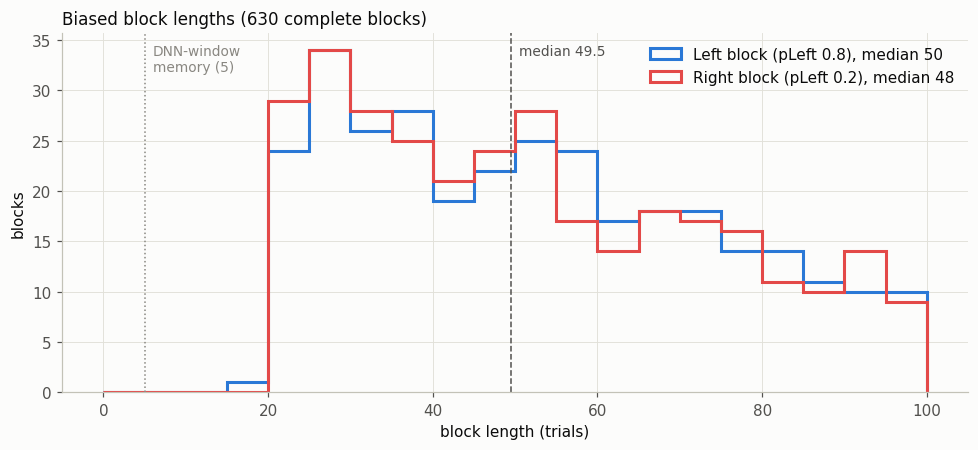

In [6]:
runs = ia.block_runs(df)
edges = np.arange(0, runs["length"].max() + 6, 5)

fig, ax = plt.subplots(figsize=(9, 4.2))
for block in (ia.LEFT_BLOCK, ia.RIGHT_BLOCK):
    lengths = runs.loc[runs["probabilityLeft"] == block, "length"]
    ax.hist(lengths, bins=edges, histtype="step", lw=2, color=ia.BLOCK_COLORS[block],
            label=f"{ia.BLOCK_LABELS[block]}, median {lengths.median():g}")
median = runs["length"].median()
ax.axvline(median, color=C["ink_secondary"], lw=1, ls="--")
ax.text(median + 1, ax.get_ylim()[1] * 0.97, f"median {median:g}", va="top",
        color=C["ink_secondary"], fontsize=9)
ax.axvline(5, color=C["muted"], lw=1, ls=":")
ax.text(6, ax.get_ylim()[1] * 0.97, "DNN-window\nmemory (5)", va="top", color=C["muted"],
        fontsize=9)
ax.set(title=f"Biased block lengths ({len(runs)} complete blocks)",
       xlabel="block length (trials)", ylabel="blocks")
ax.legend(loc="upper right")
fig.tight_layout()

opening = ia.block_runs(df, biased_only=False)
opening = opening[opening["probabilityLeft"] == ia.NEUTRAL_BLOCK]["length"]
print(f"Unbiased opening block: {opening.min()} to {opening.max()} trials")
runs.groupby("probabilityLeft")["length"].describe().round(1)

**What to notice**

- Complete biased blocks last about 20 to 99 trials (median 49.5) and look the same for both sides; the unbiased opening block is always 90 trials (89 once, after a dropped no-go trial).
- Nothing is shorter than about 20 trials, and from 20 up the counts drift down: the block length is random, so the mouse can't just count trials to predict the next switch.
- `DNN-window` sees 5 trials. That's about a tenth of a typical block and shorter than the ~10 trials the mouse takes to adapt (section 3). The window has to work from recent choices and rewards, not the block itself.

## 6. Bonus: response times

The new timing columns allow two measures, both relative to the go cue
(which coincides with stimulus onset in this task):

- **Response time** = `response_times - goCue_times`: the wheel reached the response threshold.
- **First-movement time** = `firstMovement_times - goCue_times`: the first detected wheel movement.

Harder (lower-contrast) trials should take longer, as in classic chronometric curves.

Response time: 39 trials <= 0 s and 5 missing, not shown
First-movement time: 4,493 trials <= 0 s and 4,864 missing, not shown


correct,False,True
abs_contrast,,
0.0000,0.427,0.405
0.0625,0.390,0.334
0.1250,0.369,0.292
0.2500,0.357,0.267
1.0000,0.396,0.238


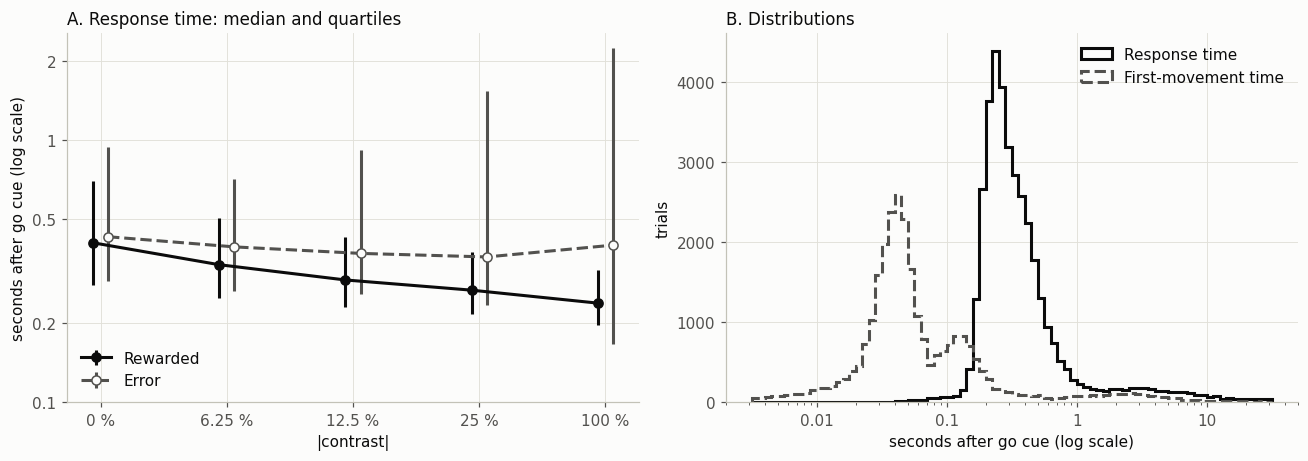

In [7]:
levels_abs = sorted(df["abs_contrast"].unique())
cpos = {c: i for i, c in enumerate(levels_abs)}
chrono = ia.chronometric(df, "response_time")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
for correct, color, ls, face, label in ((True, C["ink"], "-", C["ink"], "Rewarded"),
                                        (False, C["ink_secondary"], "--", C["surface"], "Error")):
    t = chrono[chrono["correct"] == correct]
    xs = t["abs_contrast"].map(cpos) + (-0.06 if correct else 0.06)
    ax.errorbar(xs, t["median"], yerr=[t["median"] - t["q25"], t["q75"] - t["median"]],
                color=color, ls=ls, lw=2, marker="o", ms=6, mfc=face, label=label)
ax.set_yscale("log")
ax.set_yticks([0.1, 0.2, 0.5, 1, 2], ["0.1", "0.2", "0.5", "1", "2"])
ax.minorticks_off()
ax.set_xticks(range(len(levels_abs)), [f"{100 * c:g} %" for c in levels_abs])
ax.set(title="A. Response time: median and quartiles", xlabel="|contrast|",
       ylabel="seconds after go cue (log scale)")
ax.legend(loc="lower left")

ax = axes[1]
bins = np.logspace(-2.5, 1.5, 81)
for col, color, ls, name in (("response_time", C["ink"], "-", "Response time"),
                             ("movement_time", C["ink_secondary"], "--", "First-movement time")):
    values = df[col]
    ax.hist(values[values > 0], bins=bins, histtype="step", lw=2, color=color, ls=ls,
            label=name)
    print(f"{name}: {int((values <= 0).sum()):,} trials <= 0 s and "
          f"{int(values.isna().sum()):,} missing, not shown")
ax.set_xscale("log")
ax.set_xticks([0.01, 0.1, 1, 10], ["0.01", "0.1", "1", "10"])
ax.set(title="B. Distributions", xlabel="seconds after go cue (log scale)", ylabel="trials")
ax.legend(loc="upper right")
fig.tight_layout()

chrono.pivot(index="abs_contrast", columns="correct", values="median").round(3)

**What to notice**

- On rewarded trials, response time falls with contrast, from 0.41 s at 0 % to 0.24 s at 100 %: easier decisions are faster.
- Error trials are slow at every contrast (0.36 to 0.43 s). Errors at 100 % contrast are almost as slow as guesses at 0 %, which suggests lapses of attention more than misperception.
- First-movement time behaves differently: 9,357 trials (25 %) are at or before the go cue or missing, and 75 % of the rest are under 0.1 s. In these 2019 sessions the mouse is usually already moving the wheel when the cue arrives. For this data, use response time.

## Where to go next

- **The GUI** does all of the above with filters, per session, and can download other mice: `conda activate ibl && python ibl_explorer.py`.
- **Exercises**
  - [ ] Plot block-following (section 1C) against trials per session. Is the link with short sessions real, or driven by a couple of points?
  - [ ] Why do the unbiased and right-block curves overlap at -6.25 % in section 2? (Hint: the unbiased block is always the first 90 trials of a session.)
  - [ ] Fit an exponential to the 0 % curve after the switch in section 3. What is its time constant, in trials?
  - [ ] Redo section 4 using only trials 20 or more into a block, so the mouse's lagging belief right after a switch can't pose as a history effect.
  - [ ] Download a second mouse in the GUI, save it as a CSV, and point this notebook at it. Do the same patterns hold?